### Regression

1. Data cleaning ☑
2. Data split ☑
3. EDA ☑
4. Baseline model ☑
5. Features ☑
6. Linear Regression (Ridge, Lasso) ☑ 
7. Polynomial Regression ☑

---

SUMMARY:

- `Data cleaning` ... Fixed cleaning functions 
- `EDA`
    - Added correlation table to show location alone can’t explain differences between rivers
    - Kept 3 EDA plots for cleaner report
    - Added station map (lon vs. lat, colored by median daily range in meters) to spot harbour/tide gauges<br>
      🚩**QUESTION**: Do we want to drop stations with comparatively higher median daily range as they seem to be a harbor, measuring tide gauges rather than pure river-level?
- `Features` 
    - add_features(df, cutoff) adds train-only sta_mean, sta_std, target z, sin_doy/cos_doy (+ sin2/cos2) and daily_range (median within-day range ÷ IQR, train only)
        - K = 2 (sin 2θ, cos 2θ): no improvement (RMSE(z) 1.02 vs 1.01), so K = 1 kept
        - daily_range: no improvement on its own (coefficient ≈ 0, since z already removes each station’s level and spread)
- `Model fitting`
    - 🚩all model comparisons + tuning use train ≤ 2025-08-31, scored on Sep–Nov 2025. If we trained up to 2026-08-31 and scored on autumn 2026, that “unseen” data would influence our choice of models and α, so the final score wouldn’t be an honest estimate. Sep–Nov 2026 is used once, at the end, for the chosen model
- `Baseline`: all features
    - chosen model: Seasonal LR (sin, cos) ... backed up by lasso 
    - Lasso (α loop): best α = 0.01 keeps only cos/sin (39 of 41 coefficients = 0) ... confirms season = signal
    - Ridge (α loop): no gain at any α
    - Polynomial (sin, cos, daily_range; degree 1–3): no gain, so seasonal shape doesn’t differ by river type<br>
  <u>Note.</u> sin/cos part of degree-2 polynomial = equivalent to adding second harmonic (K = 2)
    - All models plateau at RMSE(z) ≈ 1.01
    - Remaining error is most likely weather (rain events on particular days), missed by model (only date + sta.)
- `Plot`: actual level for 3 stations in autumn 2025

---

In [1]:
# Library

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import sklearn.pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

In [2]:
# Load data

river_avg = pd.read_csv("data/avg_river_levels.csv")
river_min = pd.read_csv("data/min_river_levels.csv")
river_max = pd.read_csv("data/max_river_levels.csv")

river_location = pd.read_csv("data/monitoring_locations.csv")

In [3]:
# Function 1: Reshape + merge df

def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    
    """
    INPUT:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    
    OUTPUT: 
    - river long df: df with one row per station per day and columns
    """
    
    data = [avg_df, min_df, max_df]
    labels = ["avg", "min", "max"]
    column = ["County", "Station_Name", "Observation_ID", "date"]
    start  = pd.Timestamp(start)
    long_df = {}

    for df, lab in zip(data, labels):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]  
        
        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left")
                 .merge(loc_df, on = column[0:3], how = "left"))

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")
    
    return river_long

In [4]:
# Function 2: Clean error in long_df

def clean_error(df, k = 20, cutoff = "2026-08-31"):
    
    """
    INPUT: 
    - df: long df that contains Observation_ID, date, avg, min, max, latitude, longitude
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    - cutoff: last day of training period
    
    OUTPUT:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    
    labels = ["avg", "min", "max"]
    cutoff = pd.Timestamp(cutoff) 
    df2 = df.copy()

    err = (df2[labels].isin([99999.999, -999999.999, -99]) | (df2[labels].abs() >= 9999)).any(axis = 1)
    df2.attrs["error"] = int(err.sum())
    df2.loc[err, labels] = np.nan
             
    for lab in labels:
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)
        
        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))

        sd = per_sta.transform("std")
        iqr = (q3 - q1).where(q3 - q1 > 0, sd)  # if iqr=0, use sd
        
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())        
        df2.loc[outlier, lab] = np.nan

    # blank 'impossible' days
    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan
    
    return df2

In [5]:
# Function 3: drop IDs in clean_df

def drop_ids(df, min_years = 3, cutoff = "2026-08-31"):
    
    """
    INPUT:
    - df (long+cleaned dataframe): contains Observation_ID, date, avg, min, max, latitude, longitude
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    - cutoff: data that marks the end of the period (given from the question)
    
    OUTPUT:
    - keep_df: a copy of df containing only stations we keep
    """

    cutoff = pd.Timestamp(cutoff) 
    
    train_obs = df["avg"].notna() & (df["date"] <= pd.Timestamp(cutoff))
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25

    keep_ids = years[years >= min_years].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_ids"] = int((years < min_years).sum())
    keep_df.attrs["kept_ids"] = int((years >= min_years).sum())

    return keep_df

In [6]:
# Function 4: Split df to train/test 

def make_split(df, cutoff, end, feature_cols, target):

    """
    INPUT:
    - clean_df: long df containing  Observation_ID, date, feature columns and target column
    - validation: cutoff = "2025-08-31", end = "2025-11-30"
    - final test: cutoff = "2026-08-31", end = "2026-11-30"
    - feature_cols: list of features names
    - target: target name to predict
    
    OUTPUT:
    - X_train, y_train, X_test, y_test
    """
    
    cutoff, end = pd.Timestamp(cutoff), pd.Timestamp(end)
    cols = feature_cols + [target] 

    train_df = (df[df["date"] <= cutoff]
               .dropna(subset = cols)
               .sort_values(["Observation_ID", "date"]))
    val_df = (df[(df["date"] > cutoff) & (df["date"] <= end)]
             .dropna(subset = cols)
             .sort_values(["Observation_ID", "date"]))
    

    X_train, y_train = train_df[feature_cols], train_df[target]
    X_test,  y_test  = val_df[feature_cols],  val_df[target]

    return X_train, y_train, X_test, y_test

In [7]:
river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_clean = clean_error(river_long)
river_df = drop_ids(river_clean)

river_df.attrs

{'error': 78,
 'outliers_avg': 112,
 'outliers_min': 179,
 'outliers_max': 145,
 'order_violations': 0,
 'dropped_ids': 8,
 'kept_ids': 372}

> **Pre-EDA**

In [8]:
### Data overview
labels = ["avg", "min", "max"]

cutoff_val = "2025-08-31"; end_val = "2025-11-30"      # validation
cutoff_final = "2026-08-31"; end_final = "2026-11-30"  # final test

# train_df 
train_df = river_df[river_df["date"] <= cutoff_final].copy()

train_df.info()                # -> inspect column names, types, non-null counts, memory
train_df[labels].describe()    # -> summary stats for avg/min/max
train_df[labels].isna().sum()  # -> NaNs in avg/min/max

print("Stations:", train_df["Observation_ID"].nunique())        # number of obs_id 
print("Counties:", train_df["County"].nunique())                # number of counties 
print("Dates:", train_df["date"].min().date(),  # first day 
      "to", train_df["date"].max().date())      # last date

<class 'pandas.DataFrame'>
Index: 1279680 entries, 0 to 1307199
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1279680 non-null  category      
 1   Station_Name    1279680 non-null  category      
 2   Observation_ID  1279680 non-null  category      
 3   date            1279680 non-null  datetime64[us]
 4   avg             1129123 non-null  float64       
 5   min             1129059 non-null  float64       
 6   max             1129090 non-null  float64       
 7   Latitude        1279680 non-null  float64       
 8   Longitude       1279680 non-null  float64       
dtypes: category(3), datetime64[us](1), float64(5)
memory usage: 74.5 MB
Stations: 372
Counties: 35
Dates: 2017-04-01 to 2026-08-31


In [9]:
# avg level stats for each month (seasonal pattern)

train_df["month"] = train_df["date"].dt.month
train_df.groupby("month")["avg"].describe()

,count,mean,std,min,25%,50%,75%,max
month,,,,,,,,
1,85304.0,0.806279,1.541739,-3.000,0.381,0.579,0.887,30.956
2,77542.0,0.811507,1.438894,-3.683,0.394,0.602,0.908,30.888
3,79080.0,0.743068,1.491443,-2.579,0.356,0.540,0.813,30.405
4,93593.0,0.619930,1.441187,-1.750,0.276,0.433,0.657,31.162
5,96650.0,0.533218,1.493790,-6.131,0.217,0.354,0.533,31.870
6,103828.0,0.554673,1.534254,-2.995,0.223,0.373,0.565,34.243
7,107929.0,0.550966,1.523683,-2.010,0.217,0.364,0.560,30.248
8,108420.0,0.598465,1.521156,-6.620,0.241,0.405,0.631,30.225
9,94248.0,0.630912,1.513950,-1.729,0.264,0.432,0.675,30.670


> **EDA**

In [10]:
# train_df (each station's days in time order)
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()
per_sta = train_df.groupby("Observation_ID", observed=True)["avg"]  # avg grouped by station

# z-score per station: (today's level − that station's mean) / that station's std
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")

train_df["year"] = train_df["date"].dt.year  # 2017, 2018, ...
train_df["month"] = train_df["date"].dt.month  # 1–12
train_df["doy"] = train_df["date"].dt.dayofyear  # day of year, 1–366

In [11]:
# Correlation table
train_df[["avg", "min", "max", "Latitude", "Longitude"]].corr()["avg"]

avg          1.000000
min          0.981258
max          0.981409
Latitude     0.051611
Longitude   -0.109446
Name: avg, dtype: float64

---

`COMMENT`

- **avg** almost perfectly correlated with min/max (r=0.98)
- Lat/Lon show negligible linear correlation (|r|<0.11|)<br>
  ∴ location alone cannot explain difference between rivers

---

In [12]:
# sample avg_df (with no NaNs)
sample = train_df.dropna(subset = ["avg"]).sample(5000, random_state = 0)

sample["season"] = sample["month"].map({6: "Summer", 7: "Summer", 8: "Summer",    # label Jun–Aug as Summer
                                        9: "Autumn", 10: "Autumn", 11: "Autumn"}) # label Sep–Nov as Autumn (forecast period)
                                                                                  # ... other months -> NaN

# daily range
sample["daily_range"] = sample["max"] - sample["min"]

# autumn
autumn = sample[sample["season"] == "Autumn"]

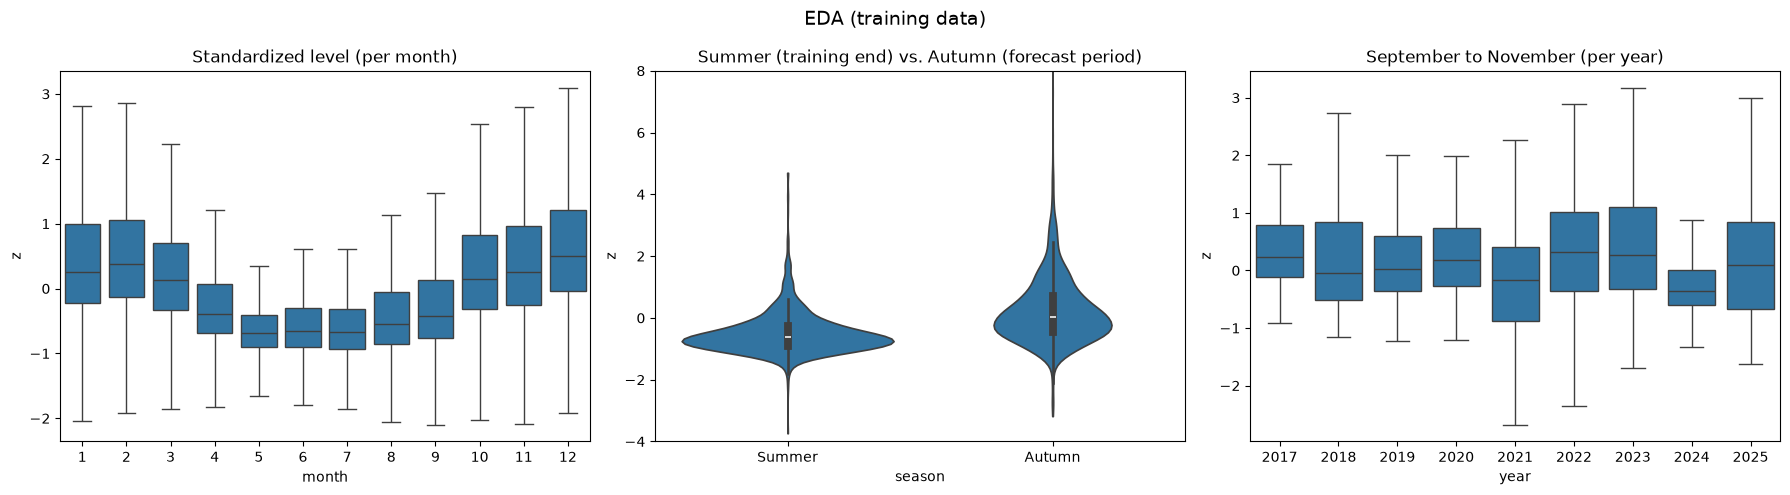

In [13]:
fig, axes = plt.subplots(1, 3, figsize = (18, 5))     


# (left) z per month (boxplot)
sns.boxplot(data = train_df, x = "month", y = "z",
            showfliers = False,  # outlier dots hidden
            ax = axes[0])
axes[0].set_title("Standardized level (per month)")

# (middle) z per season: is forecast period different from the end of training?
sns.violinplot(data = sample.dropna(subset = ["season"]), x = "season", y = "z",
               cut = 0, order = ["Summer", "Autumn"], ax = axes[1])
axes[1].set_ylim(-4, 8)
axes[1].set_title("Summer (training end) vs. Autumn (forecast period)")  

# (right) autumn per year: how much does autumn vary from year to year?
sns.boxplot(data = autumn, x = "year", y = "z", showfliers = False, ax = axes[2])
axes[2].set_title("September to November (per year)")


fig.suptitle("EDA (training data)", fontsize = 14)
plt.tight_layout()
plt.show()

---

`COMMENT`

- **z by month** (boxplot): 
    - lowest in May–Jul || highest in Dec–Feb
    - jump in Oct–Nov from Sep; expect bigger forecast errors in Oct-Nov than Sep (worth checking MAE by month)
    - rises fast (Sep-Oct) + falls slowly (Feb-May); asymmetric curve (One sin/cos pair (K=1) may miss this, so K=2 is worth testing in tuning)
    - shows clear seasonal cycle >> <u>justifies</u> sin/cos season feature
- **Summer vs. Autumn** (violin): compares end of training (Jun–Aug) with forecast months (Sep–Nov)
    - `Summer`: tight, centred around z ≈ −0.7
    - `Autumn`: centered near 0, much wider, long upper tail
    - test period behaves differently from end of training (i.e., “last known level” is NOT enough; model needs seasonal features)
    - shows shift between end of training and forecast period >> <u>justifies</u> large autumn error
- **z (Sep-Nov) by year** (boxplot):
    - autumns; genuinely differ from year-to-year
    - possible limitation; w/o additional info (weather forecast, etc.), hard to predict wet/dry autumn
    - directly about forecast period + supports limitation point

---

---

`COMMENT`

Additional EDA plot: Check if all stations record pure river-level

- Plot lon/lat scatter colored by mean level<br>
  RESULT: one station was exceptionally high (~30m)
- Median daily range per stsation<br>
  <u>NOTE.</u> Tide gauge swings several meters twice a day; river usually moves few centimeters (except in floods)<br>
  RESULT: Portpatrick, Kinlochbervie, Ullapool, Leith, Port Erin (~3-4m, all are harbours)
- Plot histogram of daily range; see if sea gauges form a separate group >> choose cut-off<br>
  RESULT: big pile <0.5m (river) → few in-between stations 0.8-1.3m → empty gap 1.35-1.95m → small cluster at 2-4m (tide gauge?)

<br>

> **QUESTION**: Drop stations with median daily range >1.5m in training data under assumption of these level reflecting tides not river flow? 

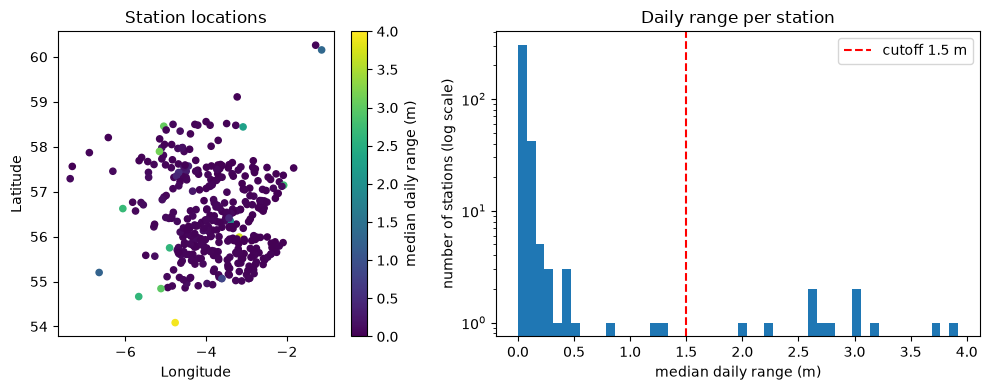

In [14]:
# one row per station: location + mean level (training data only)
sta_loc_avg = train_df.groupby("Observation_ID", observed = True).agg(lat = ("Latitude", "first"), 
                                                                      lon = ("Longitude", "first"),
                                                                      level = ("avg", "mean"))

# median daily range per station 
med_rng = (train_df["max"] - train_df["min"]).groupby(train_df["Observation_ID"], observed = True).median()


fig, axes = plt.subplots(1, 2, figsize = (10, 4), gridspec_kw = {"width_ratios": [1, 1.4]})   # map narrower, histogram wider

# (left) station map colored by mean level
sta_map = axes[0].scatter(sta_loc_avg["lon"], sta_loc_avg["lat"], c = med_rng.loc[sta_loc_avg.index], cmap = "viridis", s = 20, vmin = 0, vmax = 4)
fig.colorbar(sta_map, ax = axes[0], label = "median daily range (m)")     
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].set_title("Station locations")

# (right) histogram of median daily range
med_rng.plot.hist(bins = 50, log = True, ax = axes[1])            
axes[1].axvline(1.5, color = "red", linestyle = "--", label = "cutoff 1.5 m")
axes[1].set_xlabel("median daily range (m)"); axes[1].set_ylabel("number of stations (log scale)"); axes[1].set_title("Daily range per station")
axes[1].legend()

plt.tight_layout()
plt.show()

---

In [15]:
# get_coefs() function from lab 5
def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    
    """   
    INPUT:
    - m: sklearn LinearRegression model object (or pipeline with LinearRegression as final step)
    - plot: boolean value, should coefficients be plotted with error bars
    - feature_names: list of feature names to use in the plot 
    - figsize: tuple defining figure size
    - figtitle: string defining figure title
    - intercept: boolean value, should intercept be included in the plot

    OUTPUT:
    - Model coefficients in df for fitted linear model
    """
    
    # Extract intercept and coefficients into single array
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_], 
                        m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    
    # Extract name of features
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
        feature_names = np.concatenate((['intercept'], feature_names))
        
    # Create df
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values ("coef", ascending = False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
            
        plt.figure(figsize = figsize); plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features'); plt.xlabel('Coefficient Value')
        plt.axvline(x = 0, color = ".5")
        
        if figtitle is not None:
            plt.title(figtitle)
            
        plt.grid(); plt.show()
    
    return  w_df

In [16]:
# cos/sin for periodicity
def add_features(df, cutoff):
    
    """
    INPUT:
    - df: long df containing Observation_ID, date, avg, min, max
    - cutoff: last training date ("2025-08-31" for validation, "2026-08-31" for final test)

    OUTPUT:
    - df2: copy of df with columns added (station stats use training rows only):
        * sta_mean, sta_std: station's mean and stdev of avg level
        * z: standardized level (target)
        * daily_range: station's median (max - min), divided by its IQR of avg
        * sin_doy, cos_doy (+ sin2_doy, cos2_doy): day-of-year waves
    """
    
    df2 = df.copy()  
    cutoff = pd.Timestamp(cutoff)
    is_train = df2["date"] <= cutoff 

    train_val = df2["avg"].where(is_train)                 
    per_sta = train_val.groupby(df2["Observation_ID"], observed=True)

    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"]  = per_sta.transform("std").replace(0, np.nan)   # stdev 0 → NaN (avoid ±∞)
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]

    rng_train = (df2["max"] - df2["min"]).where(is_train)
    q1 = per_sta.transform(lambda s: s.quantile(0.25))
    q3 = per_sta.transform(lambda s: s.quantile(0.75))
    iqr = (q3 - q1).replace(0, np.nan)  # IQR 0 → NaN
    df2["daily_range"] = rng_train.groupby(df2["Observation_ID"], observed=True).transform("median") / iqr

    theta = 2 * np.pi * df2["date"].dt.dayofyear / 365.25
    df2["sin_doy"],  df2["cos_doy"]  = np.sin(theta),     np.cos(theta)       # one wave per year
    df2["sin2_doy"], df2["cos2_doy"] = np.sin(2 * theta), np.cos(2 * theta)   # two waves (K=2 check)

    return df2

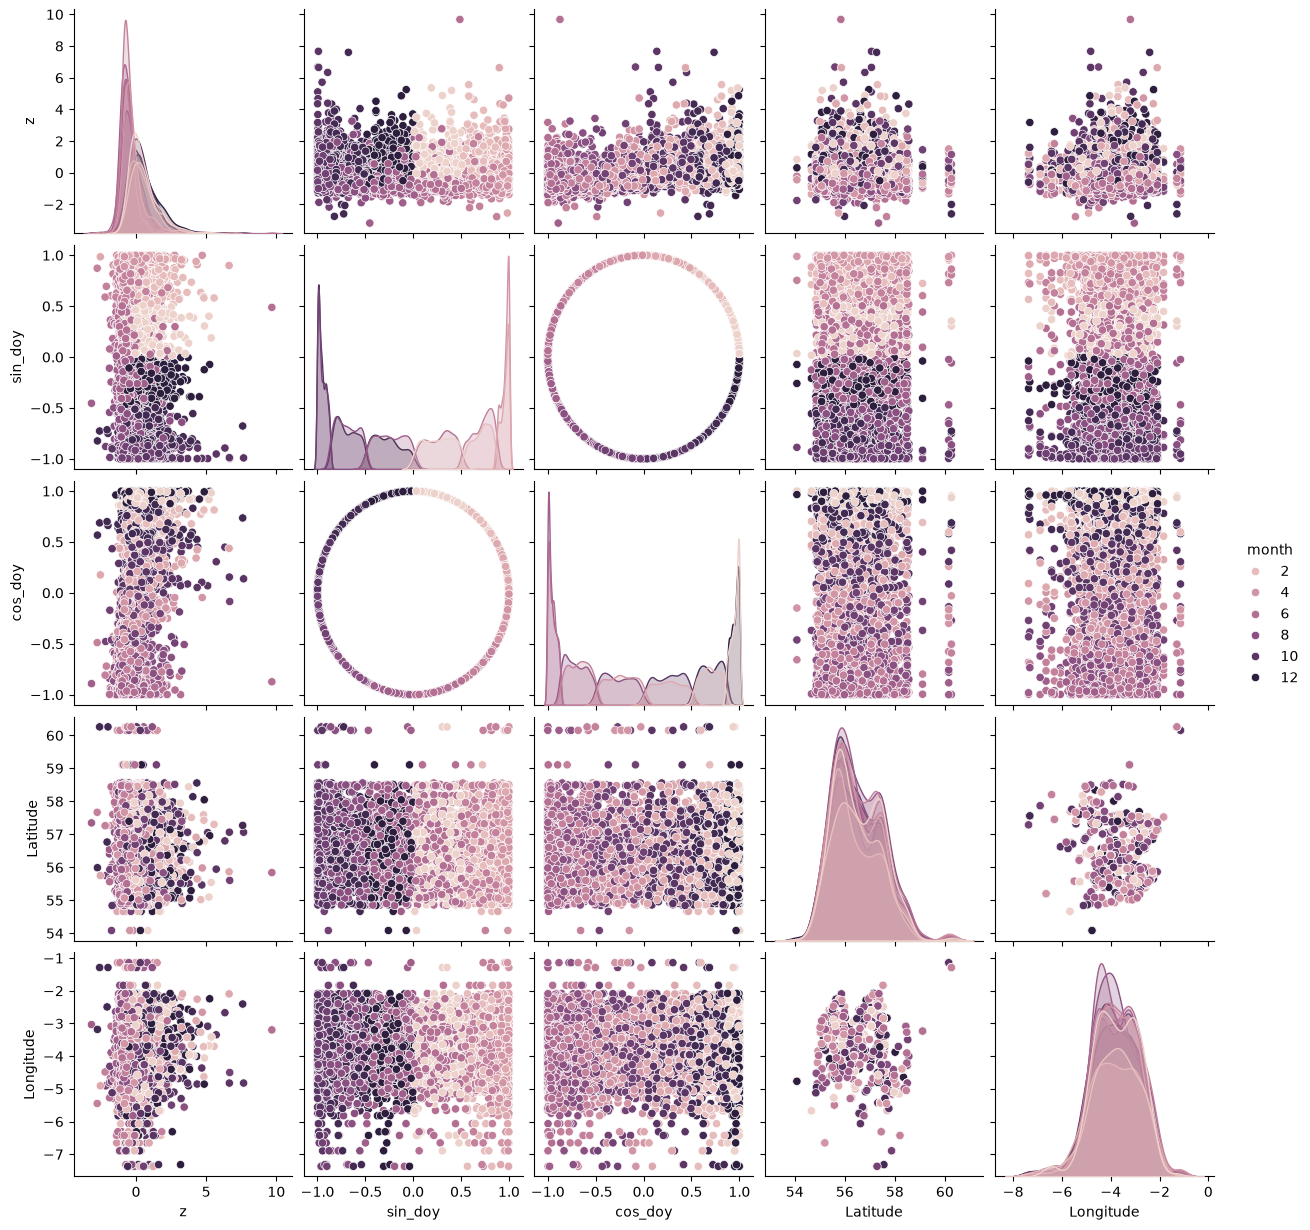

In [17]:
# add sta_mean, sta_std, z (target) and sin_doy/cos_doy (season features)
river_feat = add_features(river_df, cutoff = cutoff_val)


# pairplot 
sample = (river_feat[river_feat["date"] <= pd.Timestamp(cutoff_val)]  # training dates only
    .dropna(subset = ["z"])  
    .sample(5000, random_state = 0))

sample["month"] = sample["date"].dt.month

sns.pairplot(sample, vars = ["z", "sin_doy", "cos_doy", "Latitude", "Longitude"], hue = "month")
plt.show()

---

`COMMENT`

- `sin vs. cos`: perfect circle (months going round in order) ... _confirms encoding works_
- `Lat vs. Lon`: station map
- `z vs. lat/lon`: lat/lon (location) alone cannot explain $z$
-  `z vs. sin_doy`: vertical spread within each season (i.e., season explains only a small part of variation)

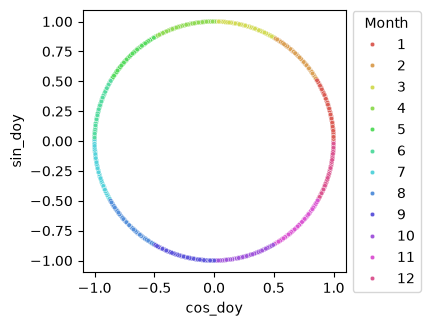

In [18]:
fig, ax = plt.subplots(figsize = (4, 3.5))

sns.scatterplot(data = sample, x = "cos_doy", y = "sin_doy", 
                hue = "month", palette = sns.color_palette("hls", 12), s = 10, ax = ax)
ax.set_aspect("equal")
ax.legend(bbox_to_anchor = (1, 1.02), loc = "upper left", title = "Month")
plt.tight_layout()
plt.show()

---

> **Baseline**

In [21]:
# Baseline model: all features 

num_cols = ["sin_doy", "cos_doy", "Latitude", "Longitude", "sta_mean", "sta_std"]
cat_cols = ["County"]

X_train_all, y_train_all, X_test_all, y_test_all = make_split(river_feat, 
                                                              feature_cols = num_cols + cat_cols, target = "z",
                                                              cutoff = cutoff_val, end = end_val)

val_df_all = river_feat.loc[X_test_all.index]

preprocess_all = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(drop = "first"), cat_cols)])
lm_all = make_pipeline(preprocess_all, LinearRegression()).fit(X_train_all, y_train_all)

pred_z_all = lm_all.predict(X_test_all)
pred_m_all = pred_z_all * val_df_all["sta_std"] + val_df_all["sta_mean"]

print("RMSE (z):", round(root_mean_squared_error(y_test_all, pred_z_all), 2),
      "\nRMSE (m):", round(root_mean_squared_error(val_df_all["avg"], pred_m_all), 2),
      "\nMAE (m): ", round(mean_absolute_error(val_df_all["avg"], pred_m_all), 2))

RMSE (z): 1.02 
RMSE (m): 0.26 
MAE (m):  0.18


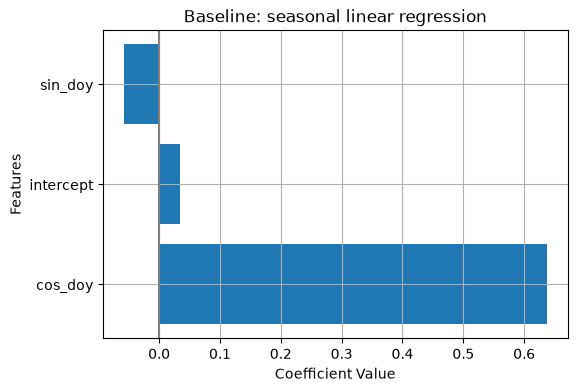

lm_sc_raw:      feature      coef
2    cos_doy  0.637066
0  intercept  0.034731
1    sin_doy -0.057765
RMSE (z): 1.01
RMSE (m): 0.26
MAE (m):  0.18


In [19]:
# split into train/test: predict z (standardized level) from season only
X_train_season, y_train_season, X_test_season, y_test_season = make_split(river_feat, 
                                                                          feature_cols = ["sin_doy", "cos_doy"], target = "z",
                                                                          cutoff = cutoff_val, end = end_val) 

val_df_season = river_feat.loc[X_test_season.index]

lm_season_raw = LinearRegression().fit(X_train_season, y_train_season)  # unscaled 
lm_season = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_season, y_train_season)

w_df_season_raw = get_coefs(lm_season_raw, plot = True, figsize = (6, 4), figtitle = "Baseline: seasonal linear regression")
print("lm_sc_raw:", w_df_season_raw)

pred_z_season = lm_season.predict(X_test_season)
pred_m_season = pred_z_season * val_df_season["sta_std"] + val_df_season["sta_mean"]

print("RMSE (z):", round(root_mean_squared_error(y_test_season, pred_z_season), 2))
print("RMSE (m):", round(root_mean_squared_error(val_df_season["avg"], pred_m_season), 2))
print("MAE (m): ", round(mean_absolute_error(val_df_season["avg"], pred_m_season), 2))

---

`COMMENT`

```
Fitted model: ẑ = 0.035 + 0.637·cos_doy − 0.058·sin_doy
```
|date | $\theta$ | $\cos(\theta)$ | $\sin(\theta)$ | $\hat z = 0.035 + 0.637·\cos_{doy} − 0.058·\sin_{doy}$ |
|-----|----------|----------------|----------------|--------------------------------------------------------|
|1 Jan| 0°       | 1              | 0              | 0.672                                                  |
|1 Apr| 90°      | 0              | 1              | -0.023                                                 |
|1 Jul| 180°     | -1             | 0              | -0.602                                                 |
|1 Oct| 270°     | 0              | -1             | 0.093                                                  |

- around Jan/Jul: peak/trough on cos curve (= peak winter/summer) 
- Jan1-Apr1 (0.672→--0.023): above normal  ... _wetter??_
- Apr1-Oct1 (-0.023→0.093): below normal  ... _dryer??_
- Oct1-Jan1 (0.093→0.672): above normal from late Sep to late Mar  ... _wetter??_
- seasonal swing; $\pm0.64$ station stdev<br>
  $\sqrt(0.637^{2} + (-0.058)^{2}) = 0.640$
- single sin/cos pair forces symmetric wave (from our boxplot in earlier cells, we know it won't be symmetric)<br>
   SUGGESTION: add second pair (`K=2`: $\sin(2\theta), \cos(2\theta)$) 

<br>

- `MAE`: average size of the miss<br>
  MAE = 0.18 ... on any day/station, prediction is about 0.18m off
- `RMSE`: square > average > sqrt ... big misses count extra<br>
  RMSE = 0.26 ... $\frac{RMSE}{MAE} \approx 0.14$ (<u>NOTE.</u> well-behaved errors; expect about 1.25) <br>
  → 1.25 < error; few days have large misses (e.g., floods; missed by season-only model)<br>
  RMSE = 1.01 ... about 1.01 of station's usual spread<br>
- Justifies autumn variation but failed to foresee day-to-day and year-to-year variation 

---

In [20]:
# add feature: cos2Θ, sin2Θ

# split into train/test: predict z (standardized level) from season only
X_train_season2, y_train_season2, X_test_season2, y_test_season2 = make_split(river_feat, feature_cols = ["sin_doy", "cos_doy", "sin2_doy", "cos2_doy"],
                                                                              target = "z", cutoff = cutoff_val, end = end_val) 

print(get_coefs(LinearRegression().fit(X_train_season2, y_train_season2)))

val_df_season2 = river_feat.loc[X_test_season2.index]
lm_season2 = LinearRegression().fit(X_train_season2, y_train_season2)

pred_z_season2 = lm_season2.predict(X_test_season2)
pred_m_season2 = pred_z_season2 * val_df_season2["sta_std"] + val_df_season2["sta_mean"]

print("RMSE (z):", round(root_mean_squared_error(y_test_season2, pred_z_season2), 2),
      "\nRMSE (m):", round(root_mean_squared_error(val_df_season2["avg"], pred_m_season2), 2),
      "\nMAE (m): ", round(mean_absolute_error(val_df_season2["avg"], pred_m_season2), 2))

     feature      coef
2    cos_doy  0.639274
3   sin2_doy  0.052483
0  intercept  0.035820
4   cos2_doy -0.006602
1    sin_doy -0.054233
RMSE (z): 1.02 
RMSE (m): 0.26 
MAE (m):  0.18


---

`COMMENT`

Adding a second harmonic ($\sin(2\theta), \cos(2\theta)$ did not improve validation error (RMSE 0.77 in both cases), so **keep the simpler model**. The errors most likely comes from day-to-day variation that seasonal curve misses. 

---

---

`COMMENT`

Add `daily_range` feature (as provided in the Clustering Section)

---

In [22]:
def add_dailyrange(df, cutoff):
    train = df[df["date"] <= cutoff]
    g = train.groupby("Observation_ID")

    iqr = g["avg"].quantile(0.75) - g["avg"].quantile(0.25)
    iqr = iqr.replace(0, np.nan)

    daily_range = (train["max"] - train["min"]).groupby(train["Observation_ID"]).median() / iqr

    df = df.copy()
    df["daily_range"] = df["Observation_ID"].map(daily_range)

    return df

In [23]:
river_feat2 = add_dailyrange(river_feat, cutoff_val)

In [24]:
# Baseline model: all features (+ daily_range)

num_cols2 = ["sin_doy", "cos_doy", "Latitude", "Longitude", "sta_mean", "sta_std", "daily_range"]
cat_cols = ["County"]

X_train_all2, y_train_all2, X_test_all2, y_test_all2 = make_split(river_feat2, feature_cols = num_cols2 + cat_cols, target = "z", cutoff = cutoff_val, end = end_val)

val_df_all2 = river_feat2.loc[X_test_all2.index]

preprocess_all2 = ColumnTransformer([("num", StandardScaler(), num_cols2),
                                ("cat", OneHotEncoder(drop = "first"), cat_cols)])
lm_all2 = make_pipeline(preprocess_all2, LinearRegression()).fit(X_train_all2, y_train_all2)

pred_z_all2 = lm_all2.predict(X_test_all2)
pred_m_all2 = pred_z_all2 * val_df_all2["sta_std"] + val_df_all2["sta_mean"]

print("RMSE (z):", round(root_mean_squared_error(y_test_all2, pred_z_all2), 2),
      "\nRMSE (m):", round(root_mean_squared_error(val_df_all2["avg"], pred_m_all2), 2),
      "\nMAE (m): ", round(mean_absolute_error(val_df_all2["avg"], pred_m_all2), 2))

RMSE (z): 1.01 
RMSE (m): 0.26 
MAE (m):  0.18


> **Regularization**

* Lasso regression

In [41]:
for i in [0.0001, 0.001, 0.01, 0.1]:
    
    lasso_rg = make_pipeline(preprocess_all, 
                             Lasso(alpha = i)).fit(X_train_all, y_train_all)
    predicted_z  = lasso_rg.predict(X_test_all)
    no_of_zeros  = (lasso_rg[-1].coef_ == 0).sum()
    
    print(i, round(root_mean_squared_error(y_test_all, predicted_z), 3), 
          no_of_zeros, "zeros of", lasso_rg[-1].coef_.size)

0.0001 1.015 26 zeros of 40
0.001 1.015 37 zeros of 40
0.01 1.014 38 zeros of 40
0.1 1.02 39 zeros of 40


---

`COMMENT`

- $\alpha = 0.0001$; RMSE (z) = 1.015; 30/41 dropped (treating most counties as pure noise)
- $\alpha = 0.001$; RMSE (z) = 1.015; 38/41 dropped
- $\alpha = 0.01$; RMSE (z) = 1.014 (BEST); 39/41 dropped; 2 survived **(probably sin/cos)**
- $\alpha = 0.1$; RMSE (z) = 1.02; 40/41 dropped; too strong

Dropping from 41 features to 2 costs nothing, so the other features most likely do not carry extra information for $z$. 

---

In [26]:
lasso_best = make_pipeline(preprocess_all, Lasso(alpha = 0.01)).fit(X_train_all, y_train_all)

w_las = get_coefs(lasso_best)
print(w_las[w_las["coef"] != 0])

        feature          coef
2  num__cos_doy  4.427995e-01
0     intercept  4.847565e-17
1  num__sin_doy -3.063862e-02


---

`COMMENT`

Lasso with $\alpha$ chosen on validation kept 2 of 41 coefficients (cos and sin of day-of-year) and matched the seasonal model’s error, confirming that location and station-type features add no predictive value once levels are standardised per station.

---

- Ridge Regression

In [40]:
for i in [1, 100, 10_000, 1_000_000]:
    
    ridge_rg = make_pipeline(preprocess_all, Ridge(alpha = i)).fit(X_train_all, y_train_all)
    predicted_z  = ridge_rg.predict(X_test_all)
    weight   = ridge_rg[-1].coef_
    
    print(i, round(root_mean_squared_error(y_test_all, predicted_z), 3),
          (weight == 0).sum(), "zeros |", round(np.abs(weight).sum(), 3), "Σ|coef|")

1 1.015 0 zeros | 0.676 Σ|coef|
100 1.015 0 zeros | 0.672 Σ|coef|
10000 1.015 0 zeros | 0.57 Σ|coef|
1000000 1.038 0 zeros | 0.251 Σ|coef|


---

`COMMENT`

- ridge shrinks but never removes unlike lasso; zeros = 0
- $\alpha$ grows; ridge squeezes every feature including $\cos$ (... cause ↑error)
- RMSE never drops below plain linear regression; no overfitting for ridge to fix

Ridge regression did not improve validation error for any $\alpha$ (RMSE(z) 1.015 for $\alpha \le 10^{4}$, rising to 1.038 at $\alpha = 10^{6}$), and unlike lasso, set no coefficients to zero. With about 1 million training rows and only 41 coefficients, the unpenalised model was not overfitting, so ridge had nothing to correct.

---

In [28]:
ridge_best = make_pipeline(preprocess_all, Ridge(alpha = 100)).fit(X_train_all, y_train_all)

w_rid = get_coefs(ridge_best)
print(w_rid[w_rid["coef"] != 0].head())

                                       feature      coef
2                                 num__cos_doy  0.452625
17                     cat__County_clackmannan  0.010967
22                       cat__County_inverness  0.008532
36  cat__County_the-stewartry-of-kirkcudbright  0.006909
28                          cat__County_orkney  0.005540


> **Polynomial Regression**

In [39]:
poly_cols = ["sin_doy", "cos_doy", "daily_range"]

X_train_p, y_train_p, X_test_p, y_test_p = make_split(river_feat2, 
                                                      feature_cols = poly_cols, target = "z", 
                                                      cutoff = cutoff_val, end = end_val)

for m in [1, 2, 3]:
    poly_reg = make_pipeline(PolynomialFeatures(degree = m, include_bias = False),
                             StandardScaler(),
                             LinearRegression()).fit(X_train_p, y_train_p)
    predicted_z = poly_reg.predict(X_test_p)
    print(m, round(root_mean_squared_error(y_test_p, predicted_z), 3), poly_reg[0].n_output_features_, "features")

1 1.015 3 features
2 1.016 9 features
3 1.014 19 features


---

`COMMENT`

<u>NOTE.</u> Lat/Lon was not used in polynomial model as standardizing per station removes location differences in level, and lasso set both to zero. 

Adding polynomial terms up to degree 3 (up to 19 features), including interactions between season and daily range, changed RMSE(z) by at most 0.002, a difference within noise, so the seasonal pattern does not differ measurably between flashy and smooth rivers. The remaining error likely came from the missing day-to-day weather information. 

---

In [35]:
poly_best = make_pipeline(PolynomialFeatures(degree = 2, include_bias = False),
                          StandardScaler(), LinearRegression()).fit(X_train_p, y_train_p)

val_df_p  = river_feat.loc[X_test_p.index]

w_p = get_coefs(poly_best)
print(w_p[w_p["coef"] != 0].head())

           feature          coef
2          cos_doy  4.725580e-01
5  sin_doy cos_doy  3.765677e-02
9    daily_range^2  5.604679e-03
4        sin_doy^2  2.141596e-03
0        intercept  6.926697e-14


Additional plot: visualize day-to-day observation

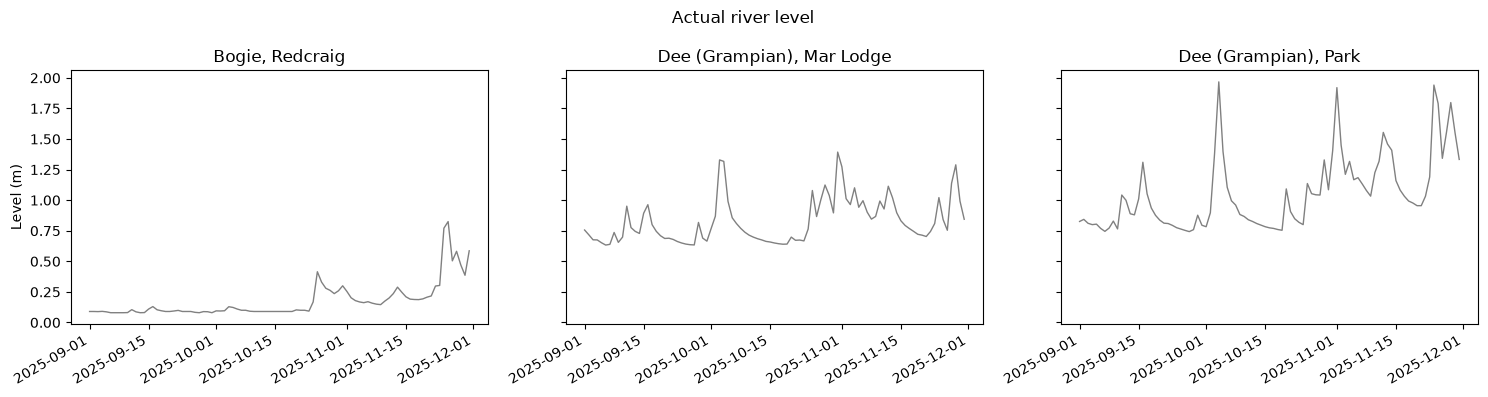

In [30]:
plot_df = val_df_all2.copy()

# 3 river stations (avoid harbours)
river_sta3 = plot_df["daily_range"] < 0.5   # e.g., 0.5 = clearly a river
stations = plot_df.loc[river_sta3, "Observation_ID"].value_counts().index[:3]   

# plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, sid in zip(axes, stations):
    s = plot_df[plot_df["Observation_ID"] == sid].sort_values("date")
    ax.plot(s["date"], s["avg"], color="grey", lw=1, label="actual")
    ax.set_title(s["Station_Name"].iloc[0])
axes[0].set_ylabel("Level (m)")

fig.suptitle("Actual river level")
fig.autofmt_xdate()          # tilts the date labels so they don't overlap
plt.tight_layout(); plt.show()

```
Summary Table
```

In [31]:
def score(name, pred_z, y_true, df):

    pred_m = pred_z * df["sta_std"] + df["sta_mean"]  # back to metres
    
    return {"model":    name,
            "RMSE (z)": root_mean_squared_error(y_true, pred_z),
            "RMSE (m)": root_mean_squared_error(df["avg"], pred_m),
            "MAE (m)":  mean_absolute_error(df["avg"], pred_m)}

In [36]:
rows = [score("Seasonal LR (sin, cos)", pred_z_season, y_test_season, val_df_season),
        score("LR (all features)", pred_z_all, y_test_all, val_df_all),
        score("Lasso (α = 0.01)", lasso_best.predict(X_test_all), y_test_all, val_df_all),
        score("Ridge (α = 100)", ridge_best.predict(X_test_all), y_test_all, val_df_all),
        score("Polynomial (degree 2)", poly_best.predict(X_test_p), y_test_p, val_df_p),]

results = pd.DataFrame(rows).set_index("model").round(3)
results

,RMSE (z),RMSE (m),MAE (m)
model,,,
"Seasonal LR (sin, cos)",1.015,0.262,0.179
LR (all features),1.015,0.262,0.179
Lasso (α = 0.01),1.014,0.262,0.178
Ridge (α = 100),1.015,0.262,0.179
Polynomial (degree 2),1.016,0.262,0.179
